# Прогноз отгрузок по маршрутам склада — финальное решение

**Автор: [stepzak](https://github.com/stepzak).** Горизонт — 8 получасовых шагов.
Ноутбук показывает EDA, проверку временной валидации, исследования и **полный inference
из сохранённых весов**. Обучение и подбор параметров здесь не запускаются.

Финальный вариант — iteration39. Public отображается как **0.326**; по сообщению автора,
он лучше session6 на **0.0004** при неокруглённом сравнении. Точное абсолютное значение
Public неизвестно. Локальный score ниже 0.322 не означает достижения этого порога на Public.

Все выводы ниже сохранены после реального последовательного серверного выполнения.
Для просмотра на GitHub вычисления и мощный компьютер не нужны.

In [1]:
from pathlib import Path
import contextlib, gc, hashlib, importlib.metadata, io, json, os, platform, sys, time
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import display, Image
from datetime import datetime, timezone

REPO = next(p for p in [Path.cwd(), *Path.cwd().parents] if (p/'bundle/metadata.json').is_file())
DATA = Path(os.environ.get('RWB_DATA_DIR', str(REPO/'data')))
DEVICE = os.environ.get('RWB_NEURAL_DEVICE', 'cpu')
(REPO/'artifacts').mkdir(exist_ok=True)
(REPO/'figures').mkdir(exist_ok=True)
started = time.monotonic()
plt.rcParams.update({'figure.figsize': (11, 4), 'axes.grid': True, 'grid.alpha': .2})
versions = {p: importlib.metadata.version(p) for p in ['numpy','pandas','scikit-learn','catboost','lightgbm']}
print('Python:', platform.python_version(), '| Устройство нейросети:', DEVICE)
print(json.dumps(versions, ensure_ascii=False, indent=2))

Python: 3.14.4 | Устройство нейросети: cuda
{
  "numpy": "2.4.6",
  "pandas": "3.0.6",
  "scikit-learn": "1.9.1",
  "catboost": "1.2.10",
  "lightgbm": "4.7.0"
}


## 1. Цель, данные и смысл полей

Прогнозируется только `target_1h`: отгрузка маршрута за последний час.
При шаге 30 минут соседние целевые окна перекрываются. Статусы 1–3 описывают количества
товаров, прошедших этапы на текущем складе за последние 30 минут, статусы 4–6 —
на предыдущем складе для товаров, направляющихся на текущий. Это оконные счётчики;
физическая вложенность этапов и точные правила дедупликации неизвестны.

Проверяем файлы по SHA-256 до загрузки: воспроизведение привязано к конкретным данным
и фиксированным исходным предсказаниям ноутбука 0328.

In [2]:
expected = json.loads((REPO/'bundle/input_hashes.json').read_text())
for name, digest in expected.items():
    with (DATA/name).open('rb') as stream:
        assert hashlib.file_digest(stream, 'sha256').hexdigest() == digest, name
sys.path.insert(0, str(REPO/'scripts'))
from artifacts import verify
print('Исходные файлы совпали с эталонными SHA-256.')
print('Проверка весов и сохранённых validation predictions:', verify())

Исходные файлы совпали с эталонными SHA-256.


Проверка весов и сохранённых validation predictions: {'verified_files': 25, 'bytes': 565551744}


In [3]:
names = ['target_1h', *[f'status_{j}' for j in range(1,7)]]
raw = pd.read_parquet(DATA/'train_solo_track.parquet', columns=['route_id','timestamp',*names])
timestamps = pd.DatetimeIndex(raw.timestamp.unique()).sort_values()
duplicates = int(raw.duplicated(['route_id','timestamp']).sum())
summary = {
    'Строк': len(raw), 'Маршрутов': raw.route_id.nunique(), 'Моментов времени': len(timestamps),
    'Начало': str(timestamps[0]), 'Конец': str(timestamps[-1]),
    'Пропущенных значений': int(raw.isna().sum().sum()), 'Дубликатов ключей': duplicates,
    'Шаг ровно 30 минут': timestamps.equals(pd.date_range(timestamps[0],timestamps[-1],freq='30min')),
    'Полная панель': len(raw) == len(timestamps)*raw.route_id.nunique() and duplicates == 0,
    'Нулевой target, %': float(raw.target_1h.eq(0).mean()*100),
    'status_6 > status_4, %': float(raw.status_6.gt(raw.status_4).mean()*100),
}
display(pd.Series(summary, name='EDA train').to_frame())
assert summary['Полная панель'] and summary['Шаг ровно 30 минут'] and duplicates == 0
assert raw[names].ge(0).all().all() and raw.notna().all().all()
del raw
_ = gc.collect()

,EDA train
Строк,4630000
Маршрутов,1000
Моментов времени,4630
Начало,2025-07-28 00:00:00
Конец,2025-11-01 10:30:00
Пропущенных значений,0
Дубликатов ключей,0
Шаг ровно 30 минут,True
Полная панель,True
"Нулевой target, %",1.508445


**Наблюдение.** Панель регулярна, грубых пропусков и дубликатов нет.
Редкие случаи `status_6 > status_4` не доказывают ошибки или вложенность статусов.
Ниже сравниваем недельные уровни и суточный профиль. Профиль рассчитан только
на обучающем участке до 3 октября; недельные уровни — описательная EDA по всему train,
они не используются как признаки или fitted-преобразования в валидации.

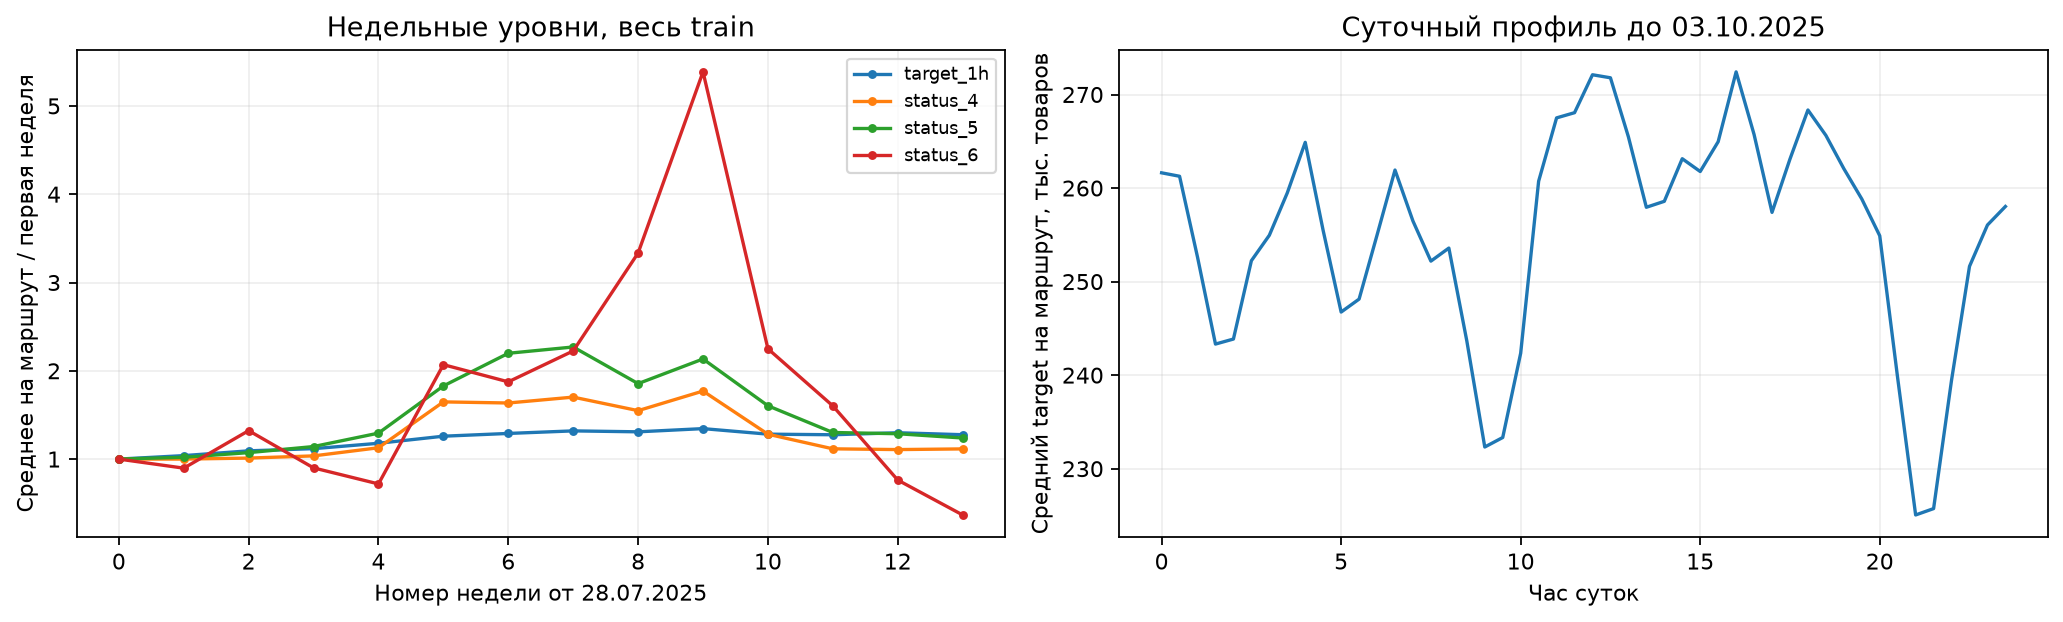

In [4]:
levels = pd.read_csv(REPO/'reports/eda_weekly_levels.csv')
slots = pd.read_csv(REPO/'reports/eda_train_slot_means.csv')
fig, axes = plt.subplots(1,2,figsize=(13,4))
for name in ['target_1h','status_4','status_5','status_6']:
    axes[0].plot(np.arange(len(levels)), levels[name]/levels[name].iloc[0], marker='.', label=name)
axes[0].set(xlabel='Номер недели от 28.07.2025',ylabel='Среднее на маршрут / первая неделя',title='Недельные уровни, весь train')
axes[0].legend(fontsize=8)
axes[1].plot(slots.slot/2, slots.target_1h/1000)
axes[1].set(xlabel='Час суток',ylabel='Средний target на маршрут, тыс. товаров',title='Суточный профиль до 03.10.2025')
fig.tight_layout();fig.savefig(REPO/'figures/eda.png',dpi=160,bbox_inches='tight')
display(Image(filename=str(REPO/'figures/eda.png')));plt.close(fig)

**Интерпретация.** Дрейф статусов 4–6 мотивирует относительные признаки: текущее значение
и короткое среднее делятся на собственное прошлое среднее, а не только на уровень target.
Это статистическая нормализация; она не доказывает физическое состояние склада.
Сезонность проверялась несколькими временными окнами. Простые persistence, daily и weekly
baseline на тех же 14 origin дают score около 0.47.

## 2. Метрика и временная валидация

Для всех оцениваемых строк: `WAPE = sum(abs(p-y))/sum(y)`,
`Rbias = sum(p-y)/sum(y)`, `score = WAPE + abs(Rbias)`.
Отрицательный Rbias означает занижение. При нулевом суммарном y оценка не определена:
код останавливается. Расчёт в float64; оценивается target, не статусы.

Rolling-origin: 6 недельных переобучений с 20 сентября по 25 октября; каждая модель
прогнозирует 7 ежедневных origin 10:30. Последние labels и fitted-преобразования раньше
origin минус 4 часа. На следующем ежедневном origin доступна его фактическая прошлая история.
Внешние веса смешивания подбирались 11–17 октября; сравнение — 18–31 октября (112000 строк).
Этот период многократно использовался в разработке и **не является слепым тестом**.

In [5]:
def metric(frame, column='prediction'):
    y = frame.y.to_numpy(dtype=np.float64)
    p = frame[column].to_numpy(dtype=np.float64)
    assert y.shape == p.shape and np.isfinite(y).all() and np.isfinite(p).all()
    assert (y >= 0).all() and (p >= 0).all() and y.sum() > 0
    error = p-y
    return pd.Series({'WAPE': np.abs(error).sum()/y.sum(),
                      'Rbias': error.sum()/y.sum(),
                      'score': (np.abs(error).sum()+abs(error.sum()))/y.sum()})

validation = pd.read_parquet(REPO/'reports/validation_predictions.parquet')
holdout = validation.loc[validation.cutoff.between('2025-10-18','2025-10-31 23:59')].copy()
assert len(holdout) == 112000 and holdout.cutoff.nunique() == 14
assert not holdout.duplicated(['cutoff','horizon','route_id']).any()
# Независимо проверяем labels по исходным данным, а не по отчёту модели.
truth = pd.read_parquet(DATA/'train_solo_track.parquet', columns=['timestamp','route_id','target_1h'])
labels = validation[['timestamp','route_id','y']].merge(truth,on=['timestamp','route_id'],validate='many_to_one')
np.testing.assert_array_equal(labels.y, labels.target_1h.astype(np.float32))
print('Независимо проверено labels:', len(labels))
del truth, labels
measured = metric(holdout)
metadata = json.loads((REPO/'bundle/metadata.json').read_text())
np.testing.assert_allclose(measured, [metadata['selection'][x] for x in measured.index],rtol=1e-12)
daily_final = holdout.groupby('cutoff').apply(lambda x: metric(x),include_groups=False)
print('Средний дневной score:', daily_final.score.mean())
display(measured.to_frame('Финальный вариант 39'))

Независимо проверено labels: 336000
Средний дневной score: 0.3350091639950611


,Финальный вариант 39
WAPE,0.317235
Rbias,-0.001091
score,0.318326


,WAPE,Rbias,score
persistence,0.466002,0.004382,0.470385
daily,0.465139,0.002813,0.467951
weekly,0.468820,0.004578,0.473398
baseline 0328,0.320090,-0.001364,0.321454
session6,0.317827,-0.001364,0.319190
финальный 39,0.317235,-0.001091,0.318326


,WAPE,Rbias,score
horizon,,,
1,0.243279,-0.009017,0.252296
2,0.302932,-0.013418,0.316349
3,0.317749,-0.018213,0.335962
4,0.320236,-0.011218,0.331454
5,0.339191,0.022457,0.361648
6,0.346883,0.031992,0.378876
7,0.336864,0.003514,0.340378
8,0.334562,-0.011276,0.345838


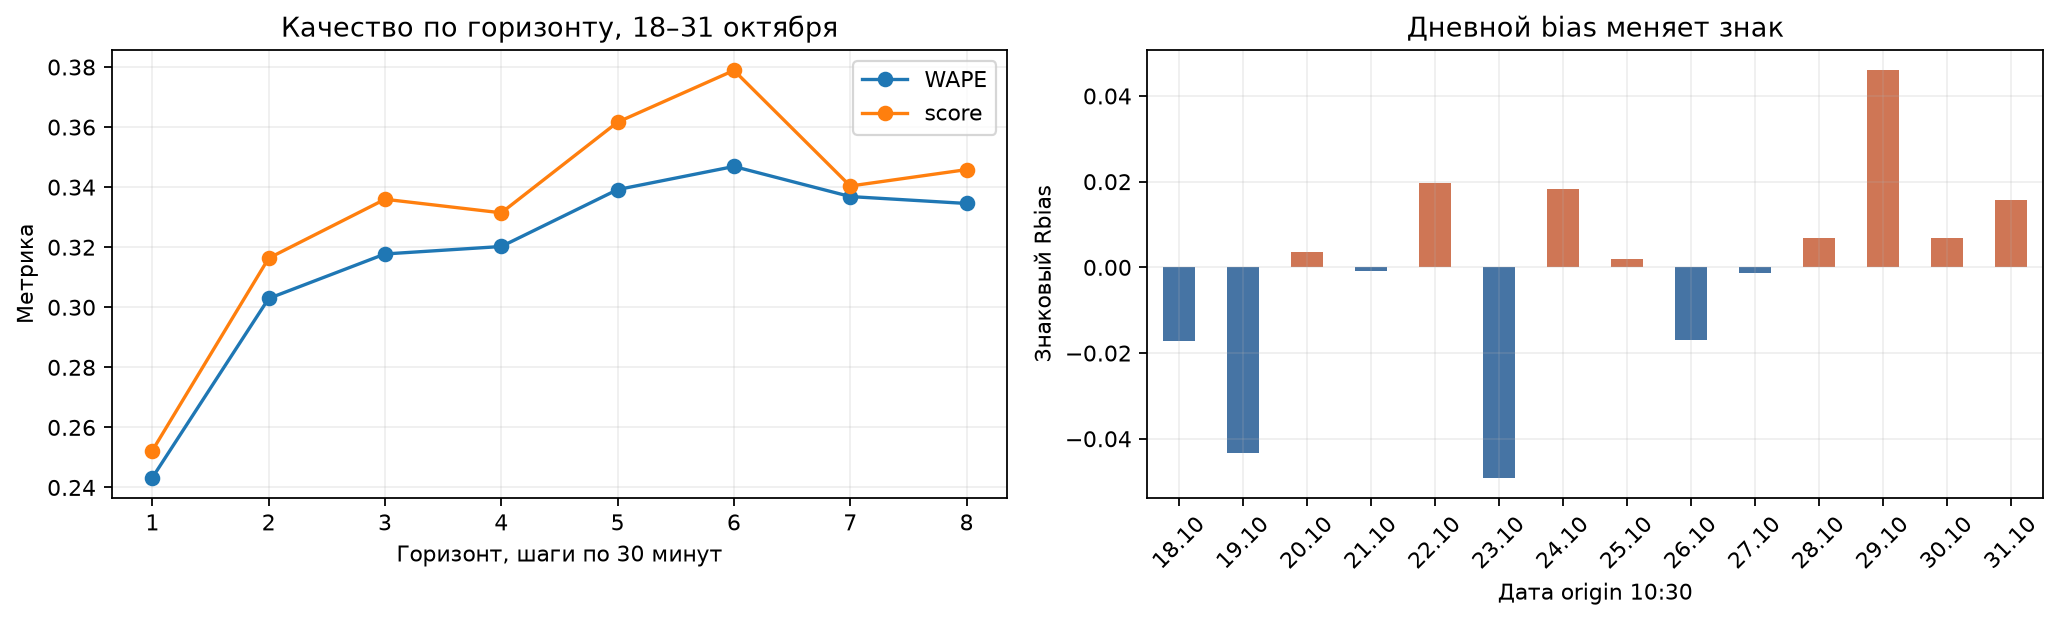

In [6]:
eda = json.loads((REPO/'reports/eda_summary.json').read_text())
rows = {k:v for k,v in eda['naive_holdout'].items()}
rows['baseline 0328'] = eda['baseline0328_holdout']
rows['session6'] = {k:metadata['baseline_session6'][k] for k in ['WAPE','Rbias','score']}
rows['финальный 39'] = measured.to_dict()
display(pd.DataFrame(rows).T.round(9))
by_horizon = holdout.groupby('horizon').apply(lambda x:metric(x),include_groups=False)
display(by_horizon.round(9))
fig, axes = plt.subplots(1,2,figsize=(13,4))
by_horizon[['WAPE','score']].plot(ax=axes[0],marker='o')
axes[0].set(xlabel='Горизонт, шаги по 30 минут',ylabel='Метрика',title='Качество по горизонту, 18–31 октября')
daily_final.Rbias.plot.bar(ax=axes[1],color=np.where(daily_final.Rbias < 0,'#4674a4','#cf7655'))
axes[1].set_xticklabels(daily_final.index.strftime('%d.%m'),rotation=45)
axes[1].set(xlabel='Дата origin 10:30',ylabel='Знаковый Rbias',title='Дневной bias меняет знак')
fig.tight_layout();fig.savefig(REPO/'figures/validation.png',dpi=160,bbox_inches='tight')
display(Image(filename=str(REPO/'figures/validation.png')));plt.close(fig)

Малый pooled bias частично возникает из компенсации дней с разными знаками ошибки.
Поэтому финальный выбор учитывал средний дневной score, улучшение WAPE в обе недели
и не менее 9 улучшенных дней из 14. Вариант 39 улучшает WAPE в 12/14 дней.

## 3. Гипотезы и итоговая модель

Проверены множитель через scipy.optimize, относительные статусы, прогноз сетевого объёма,
CatBoost для долей, динамические SVD-факторы, Fourier + AR, нейросеть долей и rolling-ансамбли.
Лучшая pooled-метрика — у 31; лучшая средняя дневная среди допустимых кандидатов — у 39.
Ниже весь журнал выделенной серии из 40 попыток; техническая неудача 8 учтена в лимите.

In [7]:
history = pd.read_csv(REPO/'reports/experiment_history.csv')
display(history[['iteration','name','status','WAPE','Rbias','score','daily_score']].round(9))
comparison = pd.read_csv(REPO/'reports/comparison.csv')
display(comparison.loc[comparison.eligible].sort_values('daily_score').head(8).round(9))
recipe = json.loads((REPO/'bundle/results/iteration_39/final_ensemble.json').read_text())
outer = json.loads((REPO/'bundle/results/iteration_39/outer.json').read_text())
display(pd.DataFrame({'iteration':recipe['selected'],'вес':recipe['weights']}))
print('Внешние веса смешивания:', outer)

,iteration,name,status,WAPE,Rbias,score,daily_score
0,1,raw_blend_scipy_multiplier,NaN,0.321734,-0.011476,0.333210,0.341481
1,2,relative_status_residual_600_depth5_shrink50,NaN,0.320146,-0.001715,0.321861,0.338442
2,3,level_normalized_weighted_residual,NaN,0.319857,-0.001725,0.321582,0.338173
3,4,level_normalized_no_route_depth6,NaN,0.320008,-0.001806,0.321814,0.338341
4,5,level_normalized_target_only,NaN,0.319892,-0.001497,0.321389,0.338948
5,6,frozen86_route_shapes_keep0328_horizon_totals,NaN,0.317827,-0.001364,0.319190,0.336039
6,7,session6_global_volume52,NaN,0.317917,-0.000428,0.318345,0.336763
7,8,session6_horizon_volume_ridge56,failed,NaN,NaN,NaN,NaN
8,9,session6_horizon_volume_ridge56_fixed,NaN,0.317872,-0.000146,0.318018,0.335833
9,10,session6_volume_consensus_global_ridge_cat,NaN,0.317964,0.000943,0.318906,0.336027


,iteration,WAPE,Rbias,score,daily_score,daily_WAPE,improved_WAPE_days,both_weeks_WAPE_improved,eligible
28,39,0.317235,-0.001091,0.318326,0.335009,0.317327,12,True,True
20,31,0.317116,-0.000146,0.317263,0.335081,0.317211,13,True,True
25,36,0.317195,-0.000146,0.317342,0.335159,0.317289,12,True,True
27,38,0.317259,-0.000493,0.317752,0.335249,0.317351,12,True,True
26,37,0.317290,-0.000146,0.317436,0.335252,0.317383,12,True,True
24,35,0.317316,-0.000146,0.317462,0.335278,0.317408,12,True,True
29,40,0.317145,-0.001364,0.318509,0.335360,0.317241,12,True,True
23,34,0.317565,-0.000146,0.317711,0.335528,0.317659,10,True,True


,iteration,вес
0,25,0.150704
1,18,0.064384
2,22,0.000000
3,31,0.315057
4,12,0.097095
5,13,0.101842
6,14,0.143576
7,27,0.127342


Внешние веса смешивания: {'shape_weight': 0.34438016307847114, 'volume_weight': 0.20508962245282525, 'fit_dates': '2025-10-11..17', 'shape_cap': 0.85}


Архитектура: session6 (фиксированный CSV 0328 + 8 LightGBM моделей маршрутов)
→ ансамбль CatBoost / factor-AR / MLP по маршрутным долям → Ridge прогноз сетевого объёма
→ weekday-калибровка → внешнее смешивание формы и объёма с session6.

Основные признаки: прошлые target, скользящие уровни/разброс, сезонные лаги и исторические
профили, относительные статусы и их изменения, текущие сетевые агрегаты, календарь,
SVD/Fourier признаки. MLP использует embedding маршрута и softmax по 1000 маршрутам.
Все будущие target доступны только как labels; будущие статусы не используются.
Подробности и ограничения исходного CSV 0328 описаны в README.

## 4. Полный inference из весов и контроль результата

Следующая ячейка заново читает данные, строит признаки для 8000 строк и выполняет все модели.
Сохранённый CSV используется **только после inference для сравнения**.
На CPU допустимы малые отклонения float32 нейросети; канонический отправленный CSV сохраняется.

In [8]:
sys.path.insert(0,str(REPO/'bundle'))
from predict_final30 import Runtime
inference_started = time.monotonic()
captured = io.StringIO()
with contextlib.redirect_stdout(captured):
    runtime = Runtime(REPO/'bundle', DATA, REPO/'artifacts/.cache', neural_device=DEVICE)
    reproduced = runtime.predict(39)
# В опубликованных выводах только относительные пути проекта.
logs = captured.getvalue().replace(str(REPO),'<project>').replace(str(DATA),'<data>')
print(logs[-4500:])
canonical = pd.read_csv(REPO/'submissions/submission_final.csv')
test = pd.read_parquet(DATA/'test_solo_track.parquet',columns=['id','timestamp','route_id'])
assert list(reproduced) == ['id','y_pred'] and len(reproduced)==8000
assert reproduced.id.is_unique and np.array_equal(reproduced.id,test.id)
assert np.isfinite(reproduced.y_pred).all() and reproduced.y_pred.ge(0).all()
assert np.array_equal(reproduced.id,canonical.id)
np.testing.assert_allclose(reproduced.y_pred,canonical.y_pred,rtol=1e-7,atol=.1)
expected_csv_hash = 'b380f83722818e26373a53f19bf89ef374c061982dc8c76cede948a65e6cf20d'
assert hashlib.sha256((REPO/'submissions/submission_final.csv').read_bytes()).hexdigest()==expected_csv_hash
delta = np.abs(reproduced.y_pred-canonical.y_pred)
from neural30 import torch
versions['torch'] = torch.__version__
run = {'executed_at_utc':datetime.now(timezone.utc).isoformat(),'selected_iteration':39,'rows':len(reproduced),'device':DEVICE,
       'inference_seconds':round(time.monotonic()-inference_started,3),
       'max_absolute_error':float(delta.max()),
       'L1_relative_error':float(delta.sum()/canonical.y_pred.sum()),
       'canonical_sha256':expected_csv_hash,'all_ids_in_test_order':True,
       'versions':versions,'python':platform.python_version()}
reproduced.to_csv(REPO/'artifacts/submission_reproduced.csv',index=False)
(REPO/'reports/notebook_execution.json').write_text(json.dumps(run,ensure_ascii=False,indent=2))
print(json.dumps(run,ensure_ascii=False,indent=2))
display(reproduced.head(8))


{
  "executed_at_utc": "2026-11-10T17:54:43.798482+00:00",
  "selected_iteration": 39,
  "rows": 8000,
  "device": "cuda",
  "inference_seconds": 9.554,
  "max_absolute_error": 4.656612873077393e-10,
  "L1_relative_error": 2.4397078509176668e-17,
  "canonical_sha256": "b380f83722818e26373a53f19bf89ef374c061982dc8c76cede948a65e6cf20d",
  "all_ids_in_test_order": true,
  "versions": {
    "numpy": "2.4.6",
    "pandas": "3.0.6",
    "scikit-learn": "1.9.1",
    "catboost": "1.2.10",
    "lightgbm": "4.7.0",
    "torch": "2.15.0+cu132"
  },
  "python": "3.14.4"
}


,id,y_pred
0,0,91793.222989
1,1,149469.416736
2,2,177001.145407
3,3,167024.750479
4,4,163277.166093
5,5,162621.567791
6,6,171717.121973
7,7,180178.780827


## 5. Результат и ограничения

Финальный локальный pooled score — **0.318325715**, средний дневной — **0.335009164**.
Public: **0.326** на уровне отображения; сообщённое улучшение к session6 — **0.0004**.
Порог Public <0.322 не достигнут. Серия из 40 попыток исчерпана.

Это воспроизведение финального inference на конкретном конкурсном срезе, а не универсальный
сервис для новых дат: исходные предсказания 0328 сохранены только для финальных 8000 id.
Валидационные прогнозы загружаются из сохранённого rolling-прогона и независимо сверяются
с train; ноутбук не переобучает 40 исторических экспериментов.
Ограничения: повторное использование holdout, малое число недель, дрейф статусов,
неполное знание механики статусов и разница локального/Public распределений.

In [9]:
print('Все ячейки завершены. Общее время, с:', round(time.monotonic()-started,2))
print('Канонический файл: submissions/submission_final.csv')
print('Новый результат: artifacts/submission_reproduced.csv')

Все ячейки завершены. Общее время, с: 14.26
Канонический файл: submissions/submission_final.csv
Новый результат: artifacts/submission_reproduced.csv
